# 6. Calidad de los logs

Los logs originales vienen de una política **uniforme al azar**. `protocolo/logs.py` genera, con los mismos ratings, los logs de un **sistema anterior** que conoce el grupo y muestra más lo que cree bueno. Usamos el preset `mixto`: cada sesión toma ε ∈ {0; 0,25; 0,5; 1} al azar, con τ = 0,25.

- **Qué se cambia:** se entrenan DT e IQL con los logs `mixto`, **sin cambiar nada más**. Mismas arquitecturas e hiperparámetros, y para IQL los mismos τ, β y γ elegidos con los logs originales.
- **Qué se vuelve a elegir:** sólo el retorno pedido al DT, en validación, porque la escala de retornos de los logs cambia.
- **Líneas base:** se ajustan con los mismos logs `mixto`.
- **Referencias:** `popularity` y el sistema anterior con ε = 0.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from src.utils import OUTPUTS
from src import reporte
pd.set_option("display.width", 200)

episodios: random 73827 | mixto 73827
retorno medio: random 64.3 | mixto 74.6


,count,mean
ε,,
0.00,18587,82.4
0.25,18460,78.0
0.50,18488,73.6
1.00,18292,64.2


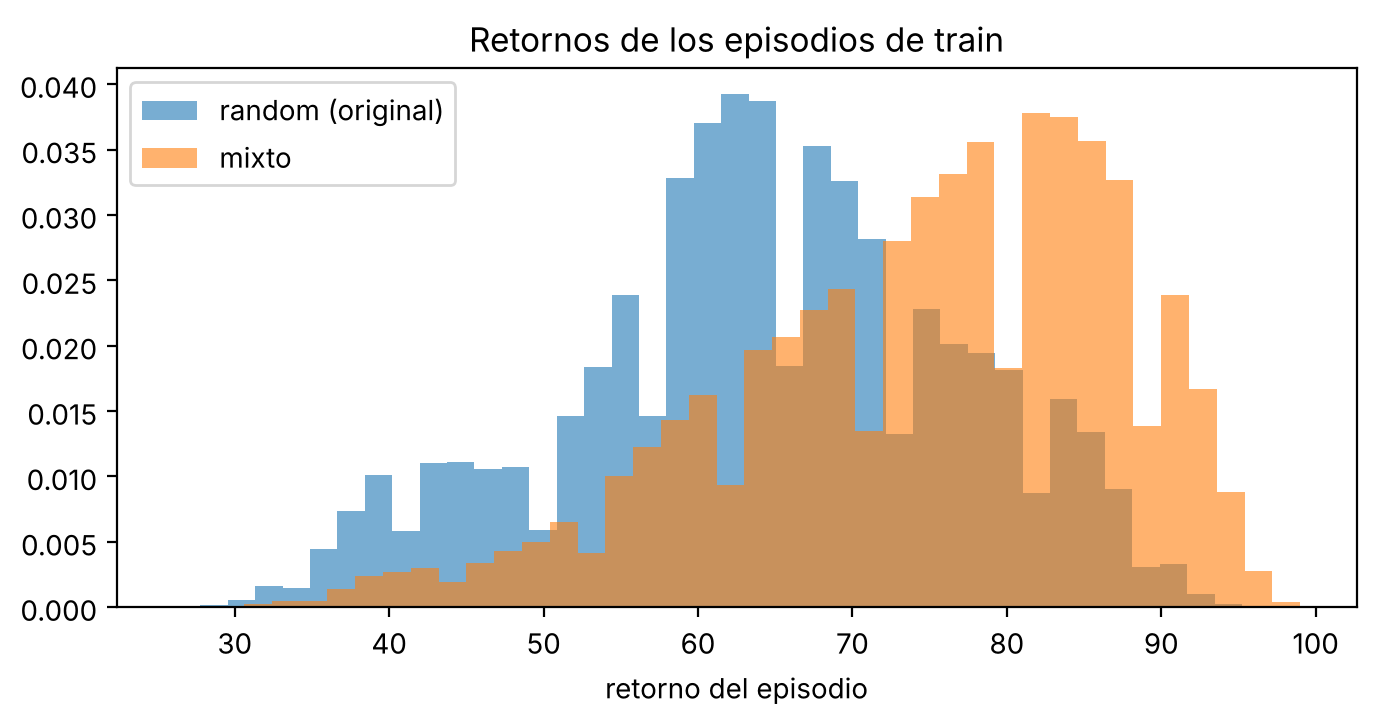

correlación (apariciones, rating medio observado) por ítem — mixto: 0.748
apariciones por ítem — mixto: mín 807 máx 8622


In [2]:
from protocolo.datos import load_train, split_by_user, make_episodes
from protocolo.logs import logged_episodes
train, _ = split_by_user(load_train("netflix"))
# Logs del sistema anterior (preset mixto). Se generan la primera vez (< 2 min) y se guardan en outputs/logs/.
mix = logged_episodes("mixto", train, train, 752, 20, seed=0, cache=OUTPUTS / "logs" / "netflix_mixto_train.npz")
z = {"items": mix.episodes.items, "ratings": mix.episodes.ratings, "epsilons": mix.epsilons}
R_rand = make_episodes(train, 20).ratings.sum(1)
R_mix = z["ratings"].sum(1)
print(f"episodios: random {len(R_rand)} | mixto {len(R_mix)}")
print(f"retorno medio: random {R_rand.mean():.1f} | mixto {R_mix.mean():.1f}")
display(pd.DataFrame({"ε": z["epsilons"], "retorno": R_mix}).groupby("ε").retorno.agg(["count", "mean"]).round(1))
plt.figure(figsize=(8, 3.5))
plt.hist(R_rand, bins=40, alpha=0.6, density=True, label="random (original)")
plt.hist(R_mix, bins=40, alpha=0.6, density=True, label="mixto")
plt.xlabel("retorno del episodio"); plt.legend(); plt.title("Retornos de los episodios de train"); plt.show()

# sesgo de selección: apariciones por ítem y su relación con el rating medio
cnt = np.bincount(z["items"].ravel(), minlength=752)
s = np.bincount(z["items"].ravel(), weights=z["ratings"].ravel(), minlength=752)
print("correlación (apariciones, rating medio observado) por ítem — mixto:", round(np.corrcoef(cnt, s / np.maximum(cnt, 1))[0, 1], 3))
print("apariciones por ítem — mixto: mín", cnt.min(), "máx", cnt.max())

## 6.1 Resultados en test: logs originales frente a `mixto`

In [3]:
def tabla(logs):
    t = reporte.main_table(logs, fmt=False)
    t = t[t.policy.isin(["popularity", "item_mean", "group_mean", "group_posterior", "sistema_anterior_eps0", "dt", "iql_pi", "iql_maxq"])]
    return t.pivot(index="policy", columns="condición", values="media")[list(reporte.COND_LABELS.values())]
comp = pd.concat({"random": tabla("random"), "mixto": tabla("mixto")}, axis=1).swaplevel(axis=1).sort_index(axis=1)
display(comp.round(3))
print("\nTabla completa con dispersión (mixto):")
display(reporte.main_table("mixto"))

condición             oculto        visible        warm-up 5, oculto        warm-up 5, visible       
                       mixto random   mixto random             mixto random              mixto random
policy                                                                                               
dt                     0.684  0.657   0.726  0.655             0.666  0.667              0.736  0.662
group_mean             0.672  0.689   0.741  0.742             0.695  0.705              0.750  0.749
group_posterior        0.705  0.707   0.741  0.742             0.727  0.729              0.750  0.749
iql_maxq               0.588  0.616   0.696  0.705             0.652  0.652              0.711  0.713
iql_pi                 0.679  0.631   0.737  0.697             0.706  0.666              0.745  0.704
item_mean              0.672  0.689   0.672  0.689             0.695  0.705              0.695  0.705
popularity             0.688 -0.058   0.688 -0.058             0.704 -0.117              0.704 -0.117
sistema_anterior_eps0  0.542    NaN   0.593    NaN             0.546    NaN              0.595    NaN


Tabla completa con dispersión (mixto):


condición,visible,oculto,"warm-up 5, visible","warm-up 5, oculto"
policy,,,,
random,-0.002 [±0.005],-0.002 [±0.005],0.003 [±0.006],0.003 [±0.006]
popularity,0.688 [±0.005],0.688 [±0.005],0.704 [±0.005],0.704 [±0.005]
item_mean,0.672 [±0.006],0.672 [±0.006],0.695 [±0.006],0.695 [±0.006]
group_mean,0.741 [±0.005],0.672 [±0.006],0.750 [±0.005],0.695 [±0.006]
group_posterior,0.741 [±0.005],0.705 [±0.005],0.750 [±0.005],0.727 [±0.005]
sistema_anterior_eps0,0.593 [±0.004],0.542 [±0.005],0.595 [±0.004],0.546 [±0.005]
dt,0.726 ± 0.002 [±0.005],0.684 ± 0.006 [±0.005],0.736 ± 0.001 [±0.005],0.666 ± 0.019 [±0.006]
iql_pi,0.737 ± 0.001 [±0.005],0.679 ± 0.005 [±0.005],0.745 ± 0.001 [±0.005],0.706 ± 0.002 [±0.005]
iql_maxq,0.696 ± 0.007 [±0.005],0.588 ± 0.011 [±0.004],0.711 ± 0.005 [±0.005],0.652 ± 0.011 [±0.005]


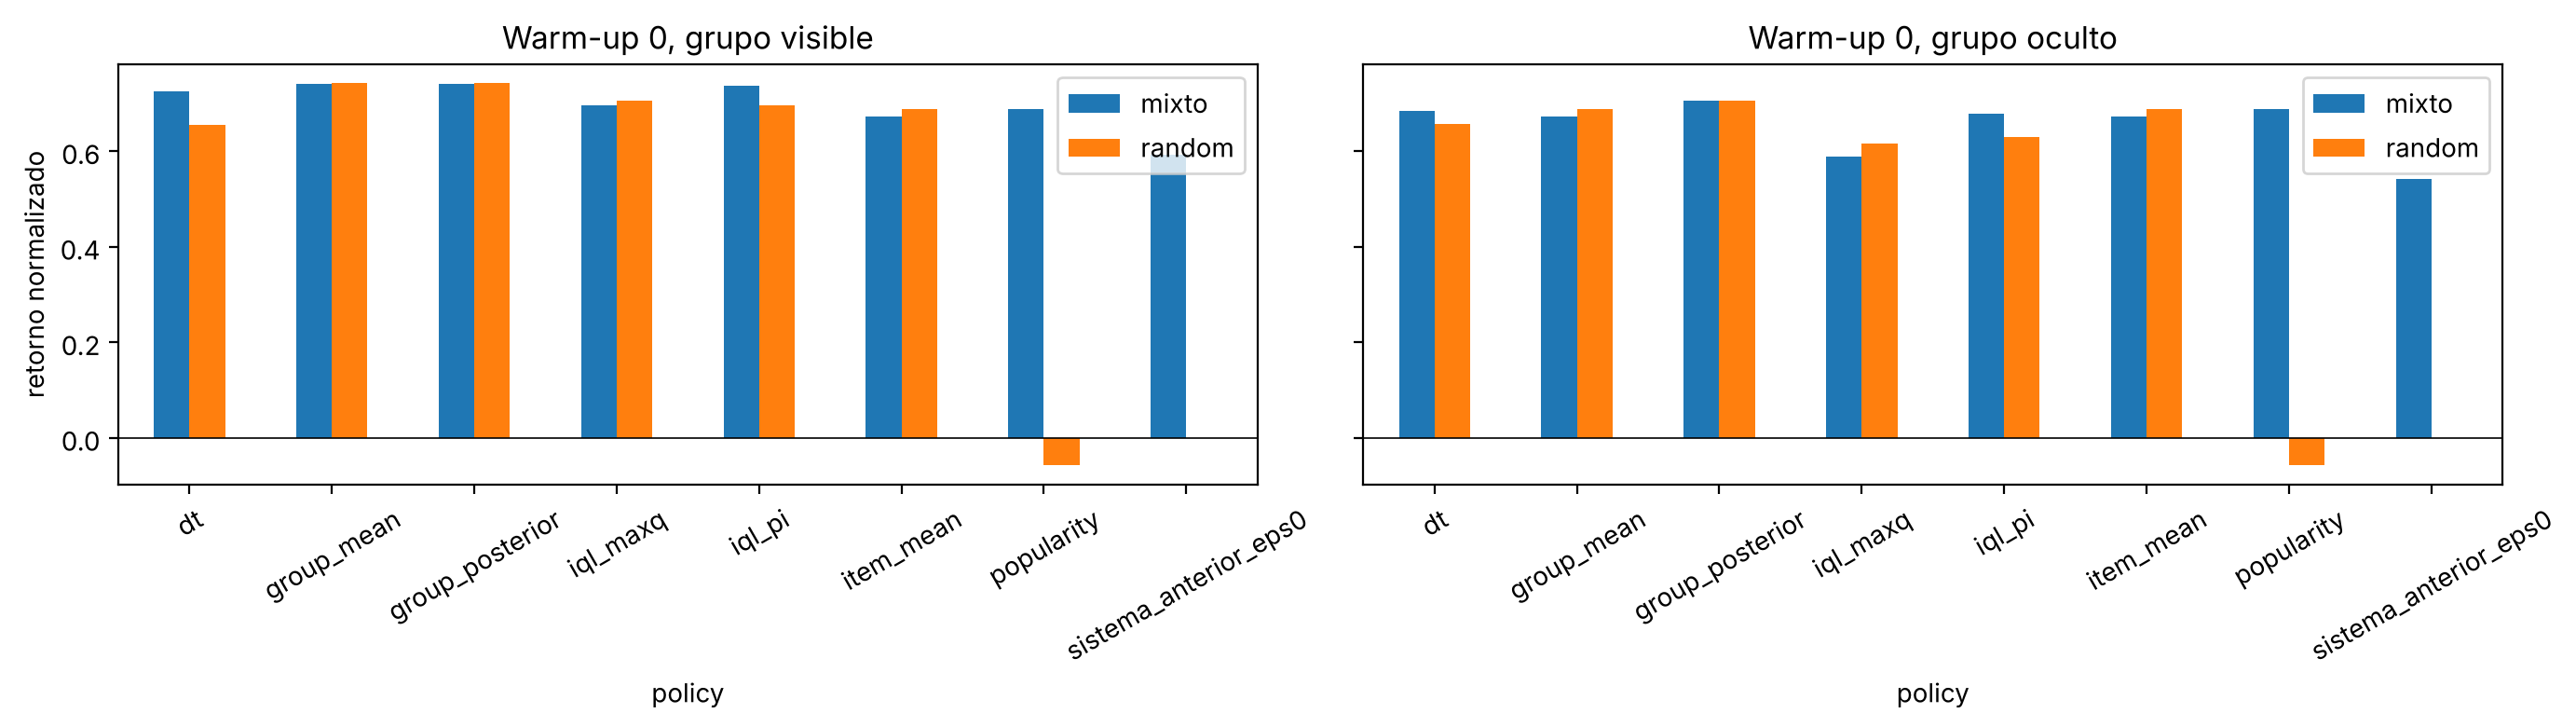

In [4]:
conds = list(reporte.COND_LABELS.values())
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, c in zip(axes, ["visible", "oculto"]):
    a = comp.xs(c, axis=1, level=0)
    a.plot.bar(ax=ax, rot=30); ax.set(title=f"Warm-up 0, grupo {c}", ylabel="retorno normalizado"); ax.axhline(0, color="k", lw=0.6)
plt.tight_layout(); plt.show()

## 6.2 Return conditioning con logs `mixto` (selección en validación)

In [5]:
sel = pd.read_csv(OUTPUTS / "seleccion" / "dt_mixto_val.csv")
tab = sel.pivot_table(index=["candidate", "target"], columns="group_visible", values="normalized")
tab.columns = ["oculto", "visible"]; tab["media"] = tab.mean(axis=1)
display(tab.sort_values("target").round(3))
print("elegido:", reporte.load_json("seleccion/dt_mixto_elegido.json"))

,,oculto,visible,media
candidate,target,,,
p10,57.0,0.177,-0.209,-0.016
p25,67.0,0.313,0.084,0.199
p50,77.0,0.414,0.376,0.395
p75,84.0,0.470,0.532,0.501
p90,89.0,0.516,0.596,0.556
p99,95.0,0.545,0.622,0.584
max,99.0,0.550,0.618,0.584
max+10,109.0,0.554,0.607,0.580


elegido: {'candidate': 'max', 'target': 99.0, 'val_normalized': 0.5841069260771811, 'criterio': 'media de normalizado en val (warm-up 0, grupo visible y oculto, 3 semillas)'}


La interpretación (qué aprende cada modelo, si supera al sistema anterior y por qué cambian `popularity` e `item_mean`) está en `docs/REPORTE.md`, sección 6.